# 01 — Data quality

Reads the canonical log and the OCaml validation report. Python does not rebuild the book.

The committed session is synthetic. A capture, if you point this notebook at one, is still market-by-price: queue position is not in the file.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

q = analysis.quality()
meta = analysis.summary()
print("synthetic:", q["synthetic"])
print("symbol:", q["symbol"])
print("notes:", q.get("notes"))
print("limitations:", q.get("limitations"))
if q["synthetic"] is not True:
    print("This file is not marked synthetic. It is still not an order-by-order feed.")
table = analysis.quality_table()
table


synthetic: True
symbol: BTCUSDT
notes: Synthetic price-level session. Not Binance market data. Queue position is planted only through the generator's own rules and is not an exchange ground truth, except where a unit test builds an explicit scenario.
limitations: ['Public Binance depth is market-by-price. Queue position is not observed.', 'rx_minus_ex mixes two clocks and is not a latency measurement.']


,item,value
0,symbol,BTCUSDT
1,synthetic,True
2,sync_mode,live
3,gaps,0
4,duplicates,0
5,crossed_observations,0
6,events_consumed,5357
7,book_hash,fd11f4eff6e97d8eb8d488bbf7d0d52c
8,count_depth,4000
9,count_snapshot,1


kind
depth       4000
trade       1356
snapshot       1
Name: count, dtype: int64
schema [1]


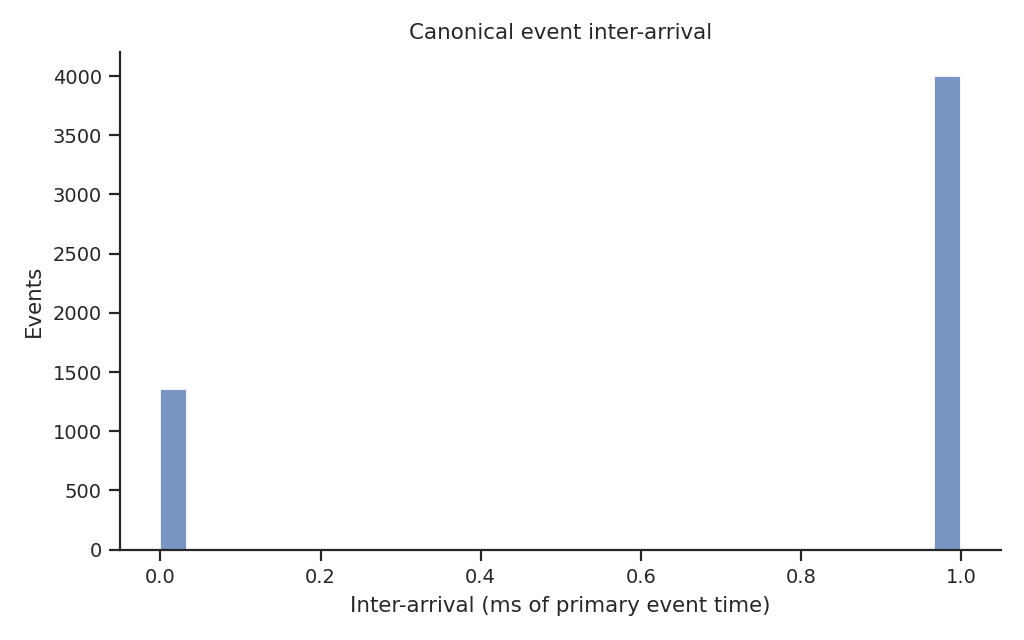

gaps 0 duplicates 0 crossed 0
rx-ex is not latency. Summary: {'n': 5356, 'min': 0, 'p50': 0, 'p90': 0, 'max': 0}


In [2]:
events = analysis.events(analysis.ROOT / "data" / "processed" / "synthetic" / "session")
if not bool(events["synthetic"].all()):
    raise RuntimeError("session events must stay marked synthetic")
print(events["kind"].value_counts())
print("schema", sorted(events["schema"].unique().tolist()))
analysis.plot_interarrival(events, analysis.FIG)
show("interarrival")
print("gaps", q["gaps"], "duplicates", q["duplicates"], "crossed", q["crossed_observations"])
print("rx-ex is not latency. Summary:", q["rx_minus_ex_us"])


Inter-arrival uses exchange time when it is non-zero, else receive time. On the synthetic session those clocks are the same by construction. On a capture they are not, and their difference is not a one-way delay.